In [1]:
import matplotlib.pyplot as plt
import pandas as pd
df=pd.read_csv("bank-full.csv", sep=";")

In [2]:
df.head(5) 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.shape

(45211, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [5]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
df.describe(include="object")

C:\Users\Dr.P\AppData\Local\Temp\ipykernel_8236\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [7]:
print(df.isna().sum())
print(df.isnull().mean()*100)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
age          0.0
job          0.0
marital      0.0
education    0.0
default      0.0
balance      0.0
housing      0.0
loan         0.0
contact      0.0
day          0.0
month        0.0
duration     0.0
campaign     0.0
pdays        0.0
previous     0.0
poutcome     0.0
y            0.0
dtype: float64


In [8]:
df["poutcome"].value_counts(dropna=False)

poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

In [9]:
df["contact"].value_counts(dropna=False)

contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

In [10]:
df["education"].value_counts(dropna=False)

education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

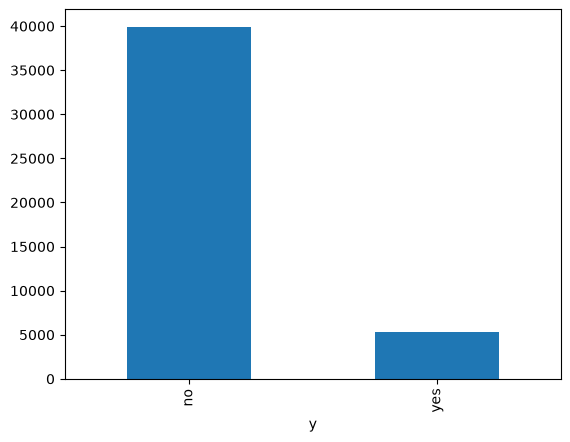

In [11]:
df["y"].value_counts().plot(kind="bar")
plt.show()

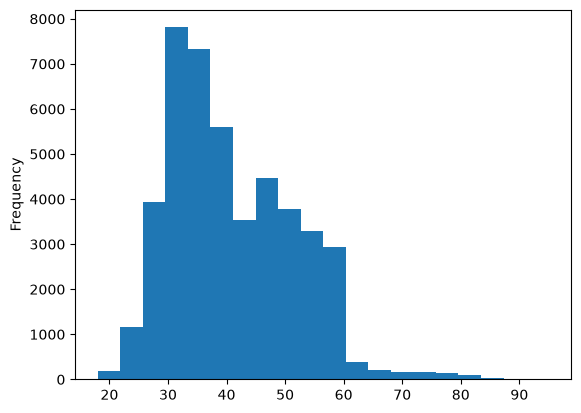

In [12]:
df["age"].plot(kind="hist",bins=20)
plt.show()


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["y"] = df["y"].map({"no" : 0 , "yes": 1})

In [15]:
print(df["y"].unique())
print(df["y"].value_counts(dropna=False))

[0 1]
y
0    39922
1     5289
Name: count, dtype: int64


In [16]:
df.corr(numeric_only=True)["y"].sort_values(ascending=False)

y           1.000000
duration    0.394521
pdays       0.103621
previous    0.093236
balance     0.052838
age         0.025155
day        -0.028348
campaign   -0.073172
Name: y, dtype: float64

In [17]:
x = df.drop(columns=["y","duration"])
y= df["y"]

In [18]:
x.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous',
       'poutcome'],
      dtype='str')

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y
)

In [20]:
num_cols = ["age","day","balance","previous","campaign","pdays"]
cat_cols =["job", "marital" , "default" , "housing" , "month" , "loan", "education","contact","poutcome"]

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [22]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("Scaler" , StandardScaler())

])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])



In [23]:
preproccessor = ColumnTransformer([ 
    ("num" , num_pipe , num_cols),
    ("cat" , cat_pipe , cat_cols)
])

In [24]:
from sklearn.neighbors import KNeighborsClassifier

model = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classifier" , KNeighborsClassifier(n_neighbors=8))
])

In [25]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model, X_train, y_train , cv=5 , scoring="recall")

In [26]:
print(scores)
print (scores.mean())


[0.15602837 0.12411348 0.15466352 0.14420804 0.1465721 ]
0.14511710082309695


In [27]:
from sklearn.linear_model import LogisticRegression
model2 = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classifier" , LogisticRegression(max_iter= 5000,class_weight="balanced"))
])

In [28]:
scores2 = cross_val_score(model2 , X_train , y_train , cv = 5 , scoring="recall")

In [29]:
print(scores2)
print (scores2.mean())


[0.63238771 0.62056738 0.63872491 0.59929078 0.61465721]
0.6211255969476472


In [30]:
from sklearn.tree import DecisionTreeClassifier
model3 = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classifier" , DecisionTreeClassifier(random_state=42 , class_weight="balanced"))
])

In [31]:
scores3 = cross_val_score(model3 , X_train , y_train , cv = 5 , scoring="recall")

In [32]:
print(scores3)
print (scores3.mean())


[0.32269504 0.30260047 0.33057851 0.28486998 0.31914894]
0.31197858664009537


In [33]:
from sklearn.ensemble import RandomForestClassifier
model4 = Pipeline ([
    ("preproccessor" , preproccessor) , 
    ("classifier" , RandomForestClassifier(n_estimators=100,random_state=42, n_jobs=-1,class_weight="balanced"))
])


In [34]:
scores4 = cross_val_score(model4 , X_train , y_train , cv = 5 , scoring="recall")

In [35]:
print(scores4)
print (scores4.mean())


[0.40307329 0.37825059 0.4025974  0.37825059 0.39007092]
0.3904485585336649


In [36]:
from sklearn.ensemble import GradientBoostingClassifier
model5 = Pipeline([
    ("preprocessor", preproccessor),
    ("classifier", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42))
])


In [37]:
scores5 = cross_val_score(model5 , X_train , y_train , cv = 5 , scoring="recall")

In [38]:
print(scores5)
print (scores5.mean())


[0.20212766 0.19030733 0.20779221 0.22340426 0.20212766]
0.20515182217309874


In [39]:
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

scores = cross_validate(
    model,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores["test_accuracy"].mean())
print("Precision:", scores["test_precision"].mean())
print("Recall:", scores["test_recall"].mean())
print("F1:", scores["test_f1"].mean())

Accuracy: 0.8888243685125019
Precision: 0.6026127340064116
Recall: 0.14511710082309695
F1: 0.2337985413280354


In [40]:

scores2 = cross_validate(
    model2,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores2["test_accuracy"].mean())
print("Precision:", scores2["test_precision"].mean())
print("Recall:", scores2["test_recall"].mean())
print("F1:", scores2["test_f1"].mean())

Accuracy: 0.7550044280276087
Precision: 0.26579807558880164
Recall: 0.6211255969476472
F1: 0.3722754507985037


In [41]:
scores3 = cross_validate(
    model3,
    X_train,
    y_train,
    cv=5,
    scoring="recall",
    return_train_score=True
)

print("Train Recall:", scores3["train_score"].mean())
print("Validation Recall:", scores3["test_score"].mean())

Train Recall: 1.0
Validation Recall: 0.31197858664009537


In [42]:

scores4 = cross_validate(
    model4,
    X_train,
    y_train,
    cv=5,
    scoring=scoring
)

print("Accuracy:", scores4["test_accuracy"].mean())
print("Precision:", scores4["test_precision"].mean())
print("Recall:", scores4["test_recall"].mean())
print("F1:", scores4["test_f1"].mean())

Accuracy: 0.8759399529718201
Precision: 0.4640300675198309
Recall: 0.3904485585336649
F1: 0.4240440436905849


In [43]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score,f1_score , precision_score , accuracy_score 


In [44]:
y_proba = cross_val_predict(model4, X_train, y_train , cv=5 , method="predict_proba")[:,1]
threshold=0.47
y_pred = (y_proba >= threshold).astype(int)

In [45]:

print("recall" , recall_score(y_train , y_pred))
print("f1" , f1_score(y_train , y_pred))
print("prec" , precision_score(y_train , y_pred))
print("acc" , accuracy_score(y_train , y_pred))

recall 0.43701252658945877
f1 0.4402905107750923
prec 0.44361804222648754
acc 0.8700232249502322


In [46]:
y_proba = cross_val_predict(model5, X_train, y_train , cv=5 , method="predict_proba")[:,1]
threshold=0.5
y_pred = (y_proba >= threshold).astype(int)

In [47]:

print("recall" , recall_score(y_train , y_pred))
print("f1" , f1_score(y_train , y_pred))
print("prec" , precision_score(y_train , y_pred))
print("acc" , accuracy_score(y_train , y_pred))

recall 0.20515244623020562
f1 0.31155778894472363
prec 0.6472781506338553
acc 0.8939393939393939


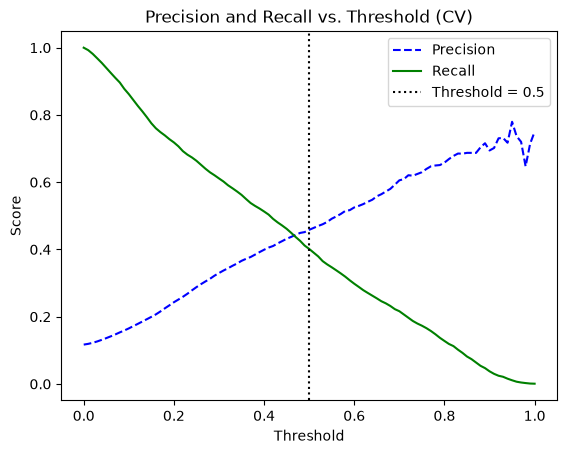

In [48]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model4,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

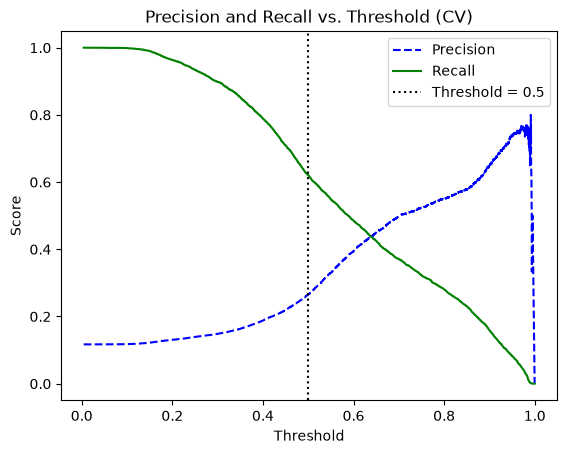

In [49]:
from sklearn.metrics import precision_recall_curve
y_proba_cv = cross_val_predict(
    model2,
    X_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

In [51]:
from sklearn.dummy import DummyClassifier
model6 = Pipeline([
    ("preprocessor", preproccessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])
model6.fit(X_train, y_train)

y_pred_1 = model6.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_1))
print("Recall:", recall_score(y_test, y_pred_1))

Accuracy: 0.8830034280659074
Recall: 0.0


در این بخش می‌بینیم که Accuracy به‌تنهایی معیار مناسبی برای ارزیابی مدل نیست؛ زیرا تعداد نمونه‌های کلاس no بسیار بیشتر از کلاس yes است. بنابراین اگر مدل تمام نمونه‌ها را no پیش‌بینی کند، Accuracy بالایی به دست می‌آورد، اما هیچ‌کدام از مشتریان مثبت را شناسایی نمی‌کند. به همین دلیل از معیارهایی مانند Recall و Precision نیز استفاده می‌کنیم.

In [52]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import fbeta_score, make_scorer

f2_scorer = make_scorer(fbeta_score, beta=2)

param_dist = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5]
}

random_search = RandomizedSearchCV(
    estimator=model4,
    param_distributions=param_dist,
    n_iter=10,
    scoring=f2_scorer,
    cv=5,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

print("Best F2:", random_search.best_score_)
print("Best Parameters:", random_search.best_params_)

Best F2: 0.5327687679660825
Best Parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 20, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 15}


In [53]:


param_dist_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "liblinear"],
    "classifier__class_weight": ["balanced"]
}

random_search_lr = RandomizedSearchCV(
    estimator=model2,
    param_distributions=param_dist_lr,
    n_iter=10,
    scoring=f2_scorer,
    cv=5,
    random_state=42,
    n_jobs=1
)

random_search_lr.fit(X_train, y_train)

print("Best F2:", random_search_lr.best_score_)
print("Best Parameters:", random_search_lr.best_params_)

Best F2: 0.4979774965106161
Best Parameters: {'classifier__solver': 'liblinear', 'classifier__class_weight': 'balanced', 'classifier__C': 0.01}


In [54]:


#param_dist_gb = {
 #   "classifier__n_estimators": [100, 200, 300],
  #  "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
 #   "classifier__max_depth": [2, 3, 4, 5],
  #  "classifier__min_samples_split": [2, 10, 20],
  #  "classifier__min_samples_leaf": [1, 2, 5]
#}

#random_search_gb = RandomizedSearchCV(
#    estimator=model5,
#    param_distributions=param_dist_gb,
#    n_iter=10,
#    scoring=f2_scorer,
#    cv=5,
#    random_state=42,
#    n_jobs=1
#)

#random_search_gb.fit(X_train, y_train)

#print("Best F2:", random_search_gb.best_score_)
#print("Best Parameters:", random_search_gb.best_params_)

In [55]:
best_model = random_search.best_estimator_

In [56]:

y_proba_cv = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

In [57]:
from sklearn.metrics import precision_recall_curve

p, r, t = precision_recall_curve(y_train, y_proba_cv)

i = (r[:-1] >= 0.6).nonzero()[0][-1]

print("Threshold:", t[i])
print("Precision:", p[i])
print("Recall:", r[i])

Threshold: 0.5007946584591291
Precision: 0.36791769308795824
Recall: 0.600094540297802


In [58]:
best_threshold = t[i]

In [59]:
final_model = random_search.best_estimator_

In [60]:
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= best_threshold).astype(int)

In [61]:

recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.6143667296786389


In [62]:

precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.36681715575620766


In [63]:

f2 = fbeta_score(y_test, y_pred, beta=2)

print("F2:", f2)

F2: 0.5413057961359093


In [64]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[6863 1122]
 [ 408  650]]


In [65]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.830808360057503


In [66]:
final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preproccessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'pdays','previous','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

In [67]:
best_threshold

np.float64(0.5007946584591291)

In [69]:
import joblib
joblib.dump({"model": final_model, "threshold": best_threshold}, "final_model.pkl")

['final_model.pkl']

In [70]:
import os
os.path.exists("final_model.pkl")

True